<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/07_evaluasi_analisis_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:

# ==========================================
# 07 - EVALUASI DAN ANALISIS KESALAHAN
# KELOMPOK 3
# ==========================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Hubungkan Google Drive
drive.mount('/content/drive')

# Lokasi dataset dan model
DATASET_DIR = "/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"

OUTPUT_DIR = os.path.dirname(DATASET_DIR)

# Baca pembagian dataset yang sama dengan Notebook 06
data = np.load(os.path.join(OUTPUT_DIR, "dataset_split.npz"))

X_test = data["X_test"]
y_test = data["y_test"]
k_test = data["k_test"]

nama_kelas = ["TAS", "BUKU GAMBAR", "LAPTOP"]

# Muat model CNN Improved
MODEL_FILE = os.path.join(OUTPUT_DIR, "model_cnn_improved.keras")

model_improved = tf.keras.models.load_model(MODEL_FILE)

# Prediksi ulang menggunakan model yang sama
prediksi_improved = model_improved.predict(X_test, verbose=0)

pred_improved = np.argmax(prediksi_improved, axis=1)

print("NOTEBOOK 07 BERHASIL DISIAPKAN!")
print("Jumlah data testing:", len(X_test))
print("Model:", MODEL_FILE)
print("Jumlah prediksi:", len(pred_improved))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NOTEBOOK 07 BERHASIL DISIAPKAN!
Jumlah data testing: 18
Model: /content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/model_cnn_improved.keras
Jumlah prediksi: 18


HASIL EVALUASI CNN IMPROVED
Accuracy : 50.00%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         TAS       0.44      0.67      0.53         6
 BUKU GAMBAR       0.56      0.83      0.67         6
      LAPTOP       0.00      0.00      0.00         6

    accuracy                           0.50        18
   macro avg       0.33      0.50      0.40        18
weighted avg       0.33      0.50      0.40        18


CONFUSION MATRIX
[[4 2 0]
 [1 5 0]
 [4 2 0]]


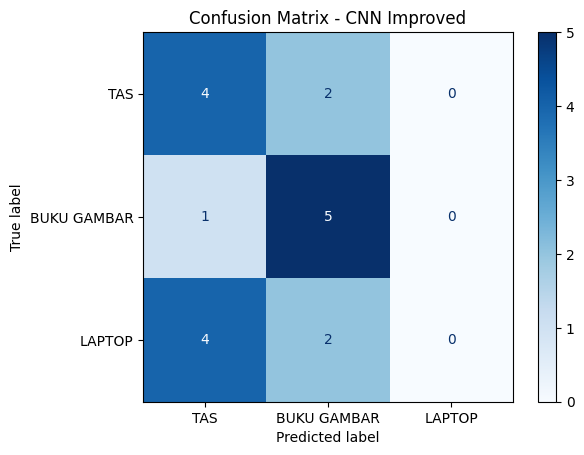

In [34]:

# ==========================================
# 1. EVALUASI PERFORMA CNN IMPROVED
# ==========================================

# Pastikan label asli berbentuk angka kelas
y_true = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test.astype(int)

# Menghitung akurasi
akurasi = accuracy_score(y_true, pred_improved)

print("=" * 50)
print("HASIL EVALUASI CNN IMPROVED")
print("=" * 50)

print(f"Accuracy : {akurasi * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_true,
    pred_improved,
    labels=[0, 1, 2],
    target_names=nama_kelas,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, pred_improved, labels=[0, 1, 2])

print("\nCONFUSION MATRIX")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nama_kelas
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - CNN Improved")
plt.show()


ANALISIS KESALAHAN PREDIKSI CNN IMPROVED
Jumlah gambar salah: 9
Jumlah gambar benar: 9

DAFTAR GAMBAR YANG SALAH DIPREDIKSI
-------------------------------------------------------
1. Gambar ke-11 | Asli: LAPTOP | Prediksi: BUKU GAMBAR | Confidence: 37.59%
2. Gambar ke-17 | Asli: LAPTOP | Prediksi: TAS | Confidence: 37.21%
3. Gambar ke-4 | Asli: BUKU GAMBAR | Prediksi: TAS | Confidence: 37.00%
4. Gambar ke-6 | Asli: TAS | Prediksi: BUKU GAMBAR | Confidence: 35.94%
5. Gambar ke-13 | Asli: LAPTOP | Prediksi: BUKU GAMBAR | Confidence: 35.82%
6. Gambar ke-8 | Asli: LAPTOP | Prediksi: TAS | Confidence: 35.82%
7. Gambar ke-18 | Asli: TAS | Prediksi: BUKU GAMBAR | Confidence: 35.73%
8. Gambar ke-10 | Asli: LAPTOP | Prediksi: TAS | Confidence: 35.28%
9. Gambar ke-1 | Asli: LAPTOP | Prediksi: TAS | Confidence: 34.73%


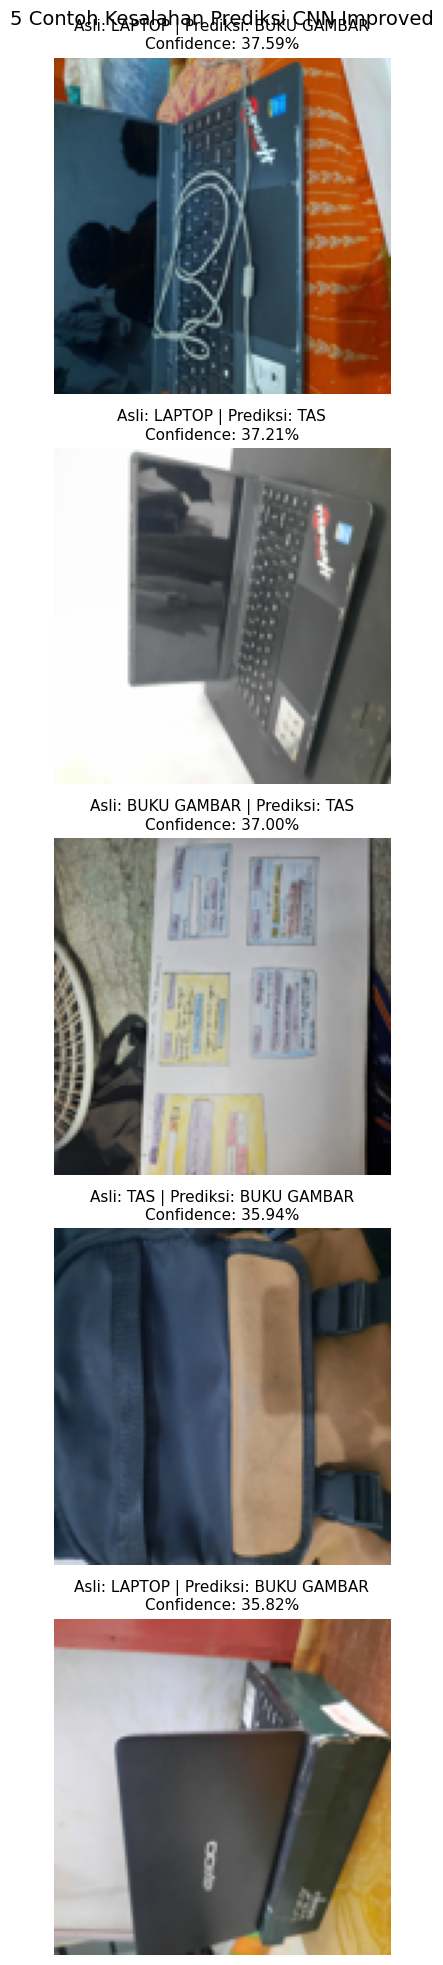

In [35]:

# ==========================================
# 2. ANALISIS KESALAHAN PREDIKSI
# CNN IMPROVED - KELOMPOK 3
# ==========================================

# Mencari indeks gambar yang salah diprediksi
wrong_indices = np.where(y_true != pred_improved)[0]

print("=" * 55)
print("ANALISIS KESALAHAN PREDIKSI CNN IMPROVED")
print("=" * 55)

print("Jumlah gambar salah:", len(wrong_indices))
print("Jumlah gambar benar:", len(y_true) - len(wrong_indices))

# Mengurutkan kesalahan berdasarkan confidence tertinggi
confidence_salah = prediksi_improved[
    wrong_indices, pred_improved[wrong_indices]
]

urutan = np.argsort(confidence_salah)[::-1]
wrong_indices = wrong_indices[urutan]

print("\nDAFTAR GAMBAR YANG SALAH DIPREDIKSI")
print("-" * 55)

for nomor, idx in enumerate(wrong_indices, start=1):
    kelas_asli = nama_kelas[y_true[idx]]
    kelas_prediksi = nama_kelas[pred_improved[idx]]
    confidence = np.max(prediksi_improved[idx]) * 100

    print(
        f"{nomor}. Gambar ke-{idx+1} | "
        f"Asli: {kelas_asli} | "
        f"Prediksi: {kelas_prediksi} | "
        f"Confidence: {confidence:.2f}%"
    )

# ==========================================
# 3. VISUALISASI 5 KESALAHAN PREDIKSI
# ==========================================

jumlah_tampil = min(5, len(wrong_indices))

fig, axes = plt.subplots(
    jumlah_tampil, 1,
    figsize=(8, jumlah_tampil * 4)
)

if jumlah_tampil == 1:
    axes = [axes]

for i, idx in enumerate(wrong_indices[:jumlah_tampil]):

    gambar = X_test[idx]

    axes[i].imshow(np.clip(gambar, 0, 1))

    kelas_asli = nama_kelas[y_true[idx]]
    kelas_prediksi = nama_kelas[pred_improved[idx]]
    confidence = np.max(prediksi_improved[idx]) * 100

    axes[i].set_title(
        f"Asli: {kelas_asli} | "
        f"Prediksi: {kelas_prediksi}\n"
        f"Confidence: {confidence:.2f}%",
        fontsize=11
    )

    axes[i].axis("off")

plt.suptitle(
    "5 Contoh Kesalahan Prediksi CNN Improved",
    fontsize=14
)

plt.tight_layout()
plt.show()
